# Jijel, August 2026 wildfires: forest loss with U-Net

Pipeline: `jijel_pre_fire.tif` and `jijel_post_fire.tif` (GEE export)
  -> U-Net forest masks -> `Forest_Loss = Forest_Pre AND NOT Forest_Post`
  -> areas, maps, NDVI/NBR evidence, comparison with WorldCover 2021.

Band order of the GEE export: 
 B2,  B3,  B4,  B8,  B11,  B12,  NDVI,  NBR, forest_mask (WorldCover 2021).

In [11]:
# Imports
import json
import warnings
from pathlib import Path

import numpy as np
import rasterio
import torch
import segmentation_models_pytorch as smp
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from tqdm.auto import tqdm

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

Device: cuda


In [12]:
# Configuration
CONFIG = {
    # -- I/O
    "PRE_TIFF":   "jijel_pre_fire_full_py.tif",
    "POST_TIFF":  "jijel_post_fire_full_py.tif",
    "MODEL_PATH": "model_2.1_Single_Wilaya_ElTarf.pth",
    "OUT_DIR":    "03_Jijel_forest_loss",

    # -- Band indices in the GEE export 
    "FEATURE_BANDS": [0, 1, 2],   # B2, B3, B4: same input as the trained model
    "NDVI_BAND":     6,
    "NBR_BAND":      7,
    "WC_BAND":       8,           # WorldCover 2021 tree cover (0/1): reference only

    # -- Model / inference (must match how the .pth was trained) 
    "ENCODER_NAME": "resnet34",
    "PATCH_SIZE":   256,
    "STRIDE_INFER": 128,
    "THRESHOLD":    0.8,
    "BATCH_SIZE":   8,            # lower it if the GPU runs out of memory

    # -- Evidence and post-processing 
    "DELTA_THRESHOLD": -0.2,      # post - pre, same convention as the paper
    "MIN_LOSS_HA":     0.0,       # optional minimum mapping unit; 0 = disabled

    # -- Display 
    "DISPLAY_STEP": 8,            # maps are block-averaged by this factor
}

OUT_DIR = Path(CONFIG["OUT_DIR"])
OUT_DIR.mkdir(parents=True, exist_ok=True)

In [13]:
# Raster checks and pixel areas
AUTHALIC_RADIUS_KM = 6371.0072   # only used if the GeoTIFF is in a geographic CRS
def check_geometry(pre_path, post_path, cfg):
    """Both TIFFs must share shape, transform and CRS, and contain the needed bands."""
    infos = []
    for path in (pre_path, post_path):
        with rasterio.open(path) as src:
            infos.append(dict(shape=(src.height, src.width), transform=src.transform,
                              crs=src.crs, count=src.count, names=src.descriptions,
                              profile=src.profile.copy()))
    a, b = infos
    assert a["shape"] == b["shape"], f"Shape mismatch: {a['shape']} vs {b['shape']}"
    assert a["transform"] == b["transform"], "Transform mismatch: re-export both TIFFs with the same region, scale and crs"
    assert a["crs"] == b["crs"], f"CRS mismatch: {a['crs']} vs {b['crs']}"
    need = max(cfg["FEATURE_BANDS"] + [cfg["NDVI_BAND"], cfg["NBR_BAND"], cfg["WC_BAND"]]) + 1
    assert a["count"] >= need and b["count"] >= need, f"TIFF has {a['count']} bands, need at least {need}"

    # Band-name check (only if GEE stored the names).
    expected = {cfg["FEATURE_BANDS"][0]: "B2", cfg["FEATURE_BANDS"][1]: "B3",
                cfg["FEATURE_BANDS"][2]: "B4", cfg["NDVI_BAND"]: "NDVI",
                cfg["NBR_BAND"]: "NBR", cfg["WC_BAND"]: "forest"}
    for label, info in (("PRE", a), ("POST", b)):
        names = info["names"]
        if all(n is None for n in names):
            print(f"[{label}] band names not stored in the TIFF: relying on configured indices")
            continue
        for idx, prefix in expected.items():
            if not (names[idx] or "").startswith(prefix):
                raise ValueError(f"[{label}] band {idx} is '{names[idx]}', expected '{prefix}*'")
    return a
    
def row_pixel_area_km2(transform, crs, height):
    """Area (km2) of one pixel for each raster row. Correct for projected and geographic CRS."""
    if transform.b != 0 or transform.d != 0:
        raise ValueError("Rotated rasters are not supported")
    if crs is None:
        raise ValueError("The GeoTIFF has no CRS")
    if crs.is_projected:
        meters_per_unit = crs.linear_units_factor[1]
        area = abs(transform.a * transform.e) * meters_per_unit ** 2 / 1e6
        return np.full(height, area, dtype=np.float64)
    # Geographic CRS (e.g. EPSG:4326): pixel area depends on latitude.
    dlon = np.radians(abs(transform.a))
    lat_top = transform.f + np.arange(height) * transform.e
    lat_bot = lat_top + transform.e
    return AUTHALIC_RADIUS_KM ** 2 * dlon * np.abs(np.sin(np.radians(lat_top)) - np.sin(np.radians(lat_bot)))


def area_km2(mask, row_area):
    """Area of a boolean mask in km2."""
    return float((mask.sum(axis=1, dtype=np.int64) * row_area).sum())


geo = check_geometry(CONFIG["PRE_TIFF"], CONFIG["POST_TIFF"], CONFIG)
H, W = geo["shape"]
ROW_AREA = row_pixel_area_km2(geo["transform"], geo["crs"], H)
print(f"Grid       : {H} x {W} px | CRS: {geo['crs']}")
print(f"Pixel area : {ROW_AREA.min() * 1e6:.1f} to {ROW_AREA.max() * 1e6:.1f} m2")
if geo["crs"].is_projected:
    if not np.isclose(ROW_AREA[0] * 1e6, 100, rtol=0.01):
        print("WARNING: pixel area is not 100 m2. Check the 'scale' used in the GEE export.")
else:
    print("Geographic CRS: pixel areas are computed per row from latitude. "
          "Exporting with crs='EPSG:32631' is still recommended.")


[PRE] band names not stored in the TIFF: relying on configured indices
[POST] band names not stored in the TIFF: relying on configured indices
Grid       : 4682 x 12094 px | CRS: EPSG:4326
Pixel area : 79.7 to 80.2 m2
Geographic CRS: pixel areas are computed per row from latitude. Exporting with crs='EPSG:32631' is still recommended.


In [14]:
# %% 4. Reading helpers
def read_band(path, band_idx):
    """One band as float32; a non-NaN nodata value is converted to NaN."""
    with rasterio.open(path) as src:
        arr = src.read(band_idx + 1).astype(np.float32)
        if src.nodata is not None and not np.isnan(src.nodata):
            arr[arr == src.nodata] = np.nan
    return arr


def read_features(path, band_idx_list):
    """Model input bands (C, H, W) as float32, plus a pixel-level validity mask."""
    with rasterio.open(path) as src:
        feats = src.read([b + 1 for b in band_idx_list]).astype(np.float32)
        if src.nodata is not None and not np.isnan(src.nodata):
            feats[feats == src.nodata] = np.nan
    # Valid = finite in every band and not an all-zero (masked) pixel.
    valid = np.isfinite(feats).all(axis=0) & ~(feats == 0).all(axis=0)
    return feats, valid


def check_reflectance_scale(feats, valid, path):
    """Catch the two silent failures: raw DN (not scaled) or scaled twice."""
    sample = feats[:, ::20, ::20][:, valid[::20, ::20]]
    if sample.size == 0:
        raise ValueError(f"{path}: no valid pixels found")
    p99 = float(np.percentile(sample, 99))
    if p99 > 5:
        raise ValueError(f"{path}: 99th percentile = {p99:.1f}. Looks like raw DN, expected reflectance 0-1")
    if p99 < 0.01:
        raise ValueError(f"{path}: 99th percentile = {p99:.5f}. Looks divided by 10000 twice")
    print(f"  reflectance check OK (99th percentile = {p99:.3f})")


In [15]:
# %% 5. Model and inference
def load_model(cfg):
    model = smp.Unet(encoder_name=cfg["ENCODER_NAME"], encoder_weights=None,
                     in_channels=len(cfg["FEATURE_BANDS"]), classes=1)
    state = torch.load(cfg["MODEL_PATH"], map_location=device, weights_only=True)
    model.load_state_dict(state)
    return model.to(device).eval()


def window_origins(h, w, patch, stride):
    """Regular grid plus a last row/column so the whole image is covered."""
    assert h >= patch and w >= patch, f"Image {h}x{w} is smaller than PATCH_SIZE={patch}"
    ys = list(range(0, h - patch + 1, stride))
    xs = list(range(0, w - patch + 1, stride))
    if ys[-1] != h - patch:
        ys.append(h - patch)
    if xs[-1] != w - patch:
        xs.append(w - patch)
    return [(y, x) for y in ys for x in xs]


@torch.no_grad()
def predict_forest(feats, valid, model, cfg, desc):
    """
    Sliding-window inference with overlap averaging, in batches.
    NaN pixels are filled with 0 so border windows are still processed (a window with
    even one NaN used to be skipped, which dropped the boundary strip of the province).
    Predictions are then restricted to valid pixels.
    """
    _, h, w = feats.shape
    p, s, bs = cfg["PATCH_SIZE"], cfg["STRIDE_INFER"], cfg["BATCH_SIZE"]
    np.nan_to_num(feats, copy=False, nan=0.0)

    origins = [(y, x) for y, x in window_origins(h, w, p, s) if valid[y:y + p, x:x + p].any()]
    prob_sum = np.zeros((h, w), np.float32)
    count = np.zeros((h, w), np.uint16)
    use_amp = device == "cuda"

    for i in tqdm(range(0, len(origins), bs), desc=desc):
        batch = origins[i:i + bs]
        xb = torch.from_numpy(np.stack([feats[:, y:y + p, x:x + p] for y, x in batch])).to(device)
        with torch.autocast(device_type=device, enabled=use_amp):
            prob = torch.sigmoid(model(xb)).float().squeeze(1).cpu().numpy()
        for (y, x), pr in zip(batch, prob):
            prob_sum[y:y + p, x:x + p] += pr
            count[y:y + p, x:x + p] += 1

    uncovered = int((valid & (count == 0)).sum())
    if uncovered:
        warnings.warn(f"{uncovered} valid pixels were not covered by any window")
    prob_map = prob_sum / np.maximum(count, 1)
    return (prob_map > cfg["THRESHOLD"]) & valid


def run_inference(path, model, cfg, label):
    print(f"\n[{label}] {path}")
    feats, valid = read_features(path, cfg["FEATURE_BANDS"])
    print(f"  valid pixels: {valid.mean() * 100:.1f}%")
    check_reflectance_scale(feats, valid, path)
    mask = predict_forest(feats, valid, model, cfg, desc=f"Inferring {label}")
    del feats
    return mask, valid


model = load_model(CONFIG)
mask_pre, valid_pre = run_inference(CONFIG["PRE_TIFF"], model, CONFIG, "pre-fire")
mask_post, valid_post = run_inference(CONFIG["POST_TIFF"], model, CONFIG, "post-fire")



[pre-fire] jijel_pre_fire_full_py.tif
  valid pixels: 52.6%
  reflectance check OK (99th percentile = 0.249)


Inferring pre-fire:   0%|          | 0/267 [00:00<?, ?it/s]


[post-fire] jijel_post_fire_full_py.tif
  valid pixels: 52.6%
  reflectance check OK (99th percentile = 0.233)


Inferring post-fire:   0%|          | 0/267 [00:00<?, ?it/s]

In [16]:
# %% 6. Forest loss (computed only where BOTH images are valid)
def remove_small_components(mask, min_pixels):
    """Optional minimum mapping unit: drop connected components smaller than min_pixels."""
    from scipy import ndimage
    labels, n = ndimage.label(mask, structure=np.ones((3, 3), dtype=bool))
    if n == 0:
        return mask
    keep = np.bincount(labels.ravel()) >= min_pixels
    keep[0] = False
    return keep[labels]


valid = valid_pre & valid_post
forest_pre = mask_pre & valid
forest_post = mask_post & valid
loss_raw = forest_pre & ~forest_post
gain = forest_post & ~forest_pre          # diagnostic only (classification noise, not regrowth)
stable = forest_pre & forest_post

if CONFIG["MIN_LOSS_HA"] > 0:
    px_km2 = float(np.median(ROW_AREA))
    min_px = int(np.ceil(CONFIG["MIN_LOSS_HA"] * 0.01 / px_km2))
    loss = remove_small_components(loss_raw, min_px)
    print(f"\nMinimum mapping unit: {CONFIG['MIN_LOSS_HA']} ha = {min_px} px")
else:
    loss = loss_raw

A_valid = area_km2(valid, ROW_AREA)
A_pre = area_km2(forest_pre, ROW_AREA)
A_post = area_km2(forest_post, ROW_AREA)
A_loss = area_km2(loss, ROW_AREA)
A_loss_raw = area_km2(loss_raw, ROW_AREA)
A_gain = area_km2(gain, ROW_AREA)
pct_lost = 100 * A_loss / A_pre if A_pre > 0 else float("nan")

print("\n" + "=" * 56)
print(f"Valid area analysed (both dates) : {A_valid:10.2f} km2")
print(f"Forest area before the fires     : {A_pre:10.2f} km2  ({A_pre * 100:,.0f} ha)")
print(f"Forest area after the fires      : {A_post:10.2f} km2  ({A_post * 100:,.0f} ha)")
print(f"Forest area lost                 : {A_loss:10.2f} km2  ({A_loss * 100:,.0f} ha)")
print(f"Percentage of forest lost        : {pct_lost:10.2f} %")
print("-" * 56)
print(f"Apparent forest gain (noise check): {A_gain:9.2f} km2")
if CONFIG["MIN_LOSS_HA"] > 0:
    print(f"Loss before small-patch filter   : {A_loss_raw:10.2f} km2")
print("=" * 56)
print("If the apparent gain is close to the loss, the loss estimate is dominated by classification noise.")


Valid area analysed (both dates) :    2384.39 km2
Forest area before the fires     :     943.74 km2  (94,374 ha)
Forest area after the fires      :     491.73 km2  (49,173 ha)
Forest area lost                 :     468.40 km2  (46,840 ha)
Percentage of forest lost        :      49.63 %
--------------------------------------------------------
Apparent forest gain (noise check):     16.39 km2
If the apparent gain is close to the loss, the loss estimate is dominated by classification noise.


In [17]:
# %% 7. Supporting evidence: NDVI and NBR change
def read_delta(band_idx):
    return read_band(CONFIG["POST_TIFF"], band_idx) - read_band(CONFIG["PRE_TIFF"], band_idx)


def evidence_table(delta, thr):
    ok = np.isfinite(delta)
    out = {}
    for name, m in (("loss", loss), ("stable_forest", stable)):
        v = delta[m & ok]
        out[name] = {"pixels": int(v.size),
                     "mean": float(v.mean()) if v.size else None,
                     "median": float(np.median(v)) if v.size else None,
                     f"share_below_{thr}": float((v < thr).mean()) if v.size else None}
    strong = (delta < thr) & ok & forest_pre
    out["strong_drop_forest_flagged_as_loss_pct"] = (
        float(100 * (strong & loss).sum() / strong.sum()) if strong.any() else None)
    return out


thr = CONFIG["DELTA_THRESHOLD"]
d_ndvi = read_delta(CONFIG["NDVI_BAND"])
d_nbr = read_delta(CONFIG["NBR_BAND"])
evidence = {"NDVI": evidence_table(d_ndvi, thr), "NBR": evidence_table(d_nbr, thr)}

both = (d_ndvi < thr) & (d_nbr < thr) & loss
evidence["loss_pixels_below_threshold_in_both_pct"] = (
    float(100 * both.sum() / loss.sum()) if loss.any() else None)

def fmt(x, spec, scale=1.0):
    return "n/a" if x is None else format(x * scale, spec)


for idx_name in ("NDVI", "NBR"):
    e = evidence[idx_name]
    print(f"\nΔ{idx_name} (post - pre)")
    print(f"  loss pixels          : mean {fmt(e['loss']['mean'], '+.3f')} | "
          f"{fmt(e['loss'][f'share_below_{thr}'], '.1f', 100)}% below {thr}")
    print(f"  stable forest pixels : mean {fmt(e['stable_forest']['mean'], '+.3f')} | "
          f"{fmt(e['stable_forest'][f'share_below_{thr}'], '.1f', 100)}% below {thr}")
    print(f"  forest pixels with strong drop that are flagged as loss: "
          f"{fmt(e['strong_drop_forest_flagged_as_loss_pct'], '.1f')}%")
print(f"\nLoss pixels below {thr} in BOTH indices: "
      f"{fmt(evidence['loss_pixels_below_threshold_in_both_pct'], '.1f')}%")
print("Reading guide: loss pixels should show a clearly stronger drop than stable forest pixels.")



ΔNDVI (post - pre)
  loss pixels          : mean -0.413 | 76.0% below -0.2
  stable forest pixels : mean -0.013 | 0.5% below -0.2
  forest pixels with strong drop that are flagged as loss: 99.3%

ΔNBR (post - pre)
  loss pixels          : mean -0.631 | 79.6% below -0.2
  stable forest pixels : mean -0.016 | 0.6% below -0.2
  forest pixels with strong drop that are flagged as loss: 99.3%

Loss pixels below -0.2 in BOTH indices: 75.9%
Reading guide: loss pixels should show a clearly stronger drop than stable forest pixels.


In [18]:
# %% 8. External reference: pre-fire U-Net map vs WorldCover 2021
def confusion_metrics(pred, ref, domain, eps=1e-9):
    p, t = pred[domain], ref[domain]
    TP = int((p & t).sum()); FP = int((p & ~t).sum())
    FN = int((~p & t).sum()); TN = int((~p & ~t).sum())
    total = TP + FP + FN + TN
    po = (TP + TN) / (total + eps)
    pe = ((TP + FP) * (TP + FN) + (TN + FN) * (TN + FP)) / (total ** 2 + eps)
    return {"TP": TP, "FP": FP, "FN": FN, "TN": TN,
            "accuracy_pct": 100 * po,
            "precision": TP / (TP + FP + eps), "recall": TP / (TP + FN + eps),
            "f1": 2 * TP / (2 * TP + FP + FN + eps), "iou": TP / (TP + FP + FN + eps),
            "kappa": (po - pe) / (1 - pe + eps)}


wc_raw = read_band(CONFIG["PRE_TIFF"], CONFIG["WC_BAND"])
wc_domain = valid & np.isfinite(wc_raw)
wc_forest = (wc_raw == 1)
wc_metrics = confusion_metrics(forest_pre, wc_forest, wc_domain)
A_wc = area_km2(wc_forest & wc_domain, ROW_AREA)

print(f"\nForest_Pre (U-Net) vs WorldCover 2021 tree cover, {wc_domain.mean() * 100:.1f}% of the raster compared")
print(f"  U-Net forest : {A_pre:8.2f} km2 | WorldCover forest: {A_wc:8.2f} km2")
print(f"  Acc {wc_metrics['accuracy_pct']:.2f}% | Kappa {wc_metrics['kappa']:.4f} | "
      f"Precision {wc_metrics['precision']:.4f} | Recall {wc_metrics['recall']:.4f} | "
      f"F1 {wc_metrics['f1']:.4f} | IoU {wc_metrics['iou']:.4f}")
print("Note: WorldCover is a 2021 product and the imagery is 2026, so small differences are expected.")


Forest_Pre (U-Net) vs WorldCover 2021 tree cover, 52.6% of the raster compared
  U-Net forest :   943.74 km2 | WorldCover forest:  1434.39 km2
  Acc 72.84% | Kappa 0.4788 | Precision 0.9168 | Recall 0.6033 | F1 0.7277 | IoU 0.5720
Note: WorldCover is a 2021 product and the imagery is 2026, so small differences are expected.


In [19]:
# %% 9. Save rasters and numbers
def save_mask(path, mask, valid, profile):
    prof = profile.copy()
    for key in ("blockxsize", "blockysize", "tiled", "photometric", "interleave"):
        prof.pop(key, None)
    prof.update(driver="GTiff", count=1, dtype="uint8", nodata=255, compress="lzw")
    with rasterio.open(path, "w", **prof) as dst:
        dst.write(np.where(valid, mask, 255).astype(np.uint8), 1)


for name, m in (("forest_pre", forest_pre), ("forest_post", forest_post), ("forest_loss", loss)):
    save_mask(OUT_DIR / f"{name}.tif", m, valid, geo["profile"])

results = {
    "config": {k: CONFIG[k] for k in ("PATCH_SIZE", "STRIDE_INFER", "THRESHOLD", "DELTA_THRESHOLD", "MIN_LOSS_HA")},
    "areas_km2": {"valid": A_valid, "forest_pre": A_pre, "forest_post": A_post,
                  "forest_loss": A_loss, "forest_loss_before_filter": A_loss_raw,
                  "apparent_gain": A_gain, "worldcover_forest": A_wc},
    "percent_forest_lost": pct_lost,
    "evidence": evidence,
    "worldcover_comparison": wc_metrics,
}
with open(OUT_DIR / "results.json", "w") as f:
    json.dump(results, f, indent=2)
print(f"\nSaved rasters (uint8, 255 = invalid) and results.json in {OUT_DIR}/")


Saved rasters (uint8, 255 = invalid) and results.json in 03_Jijel_forest_loss/


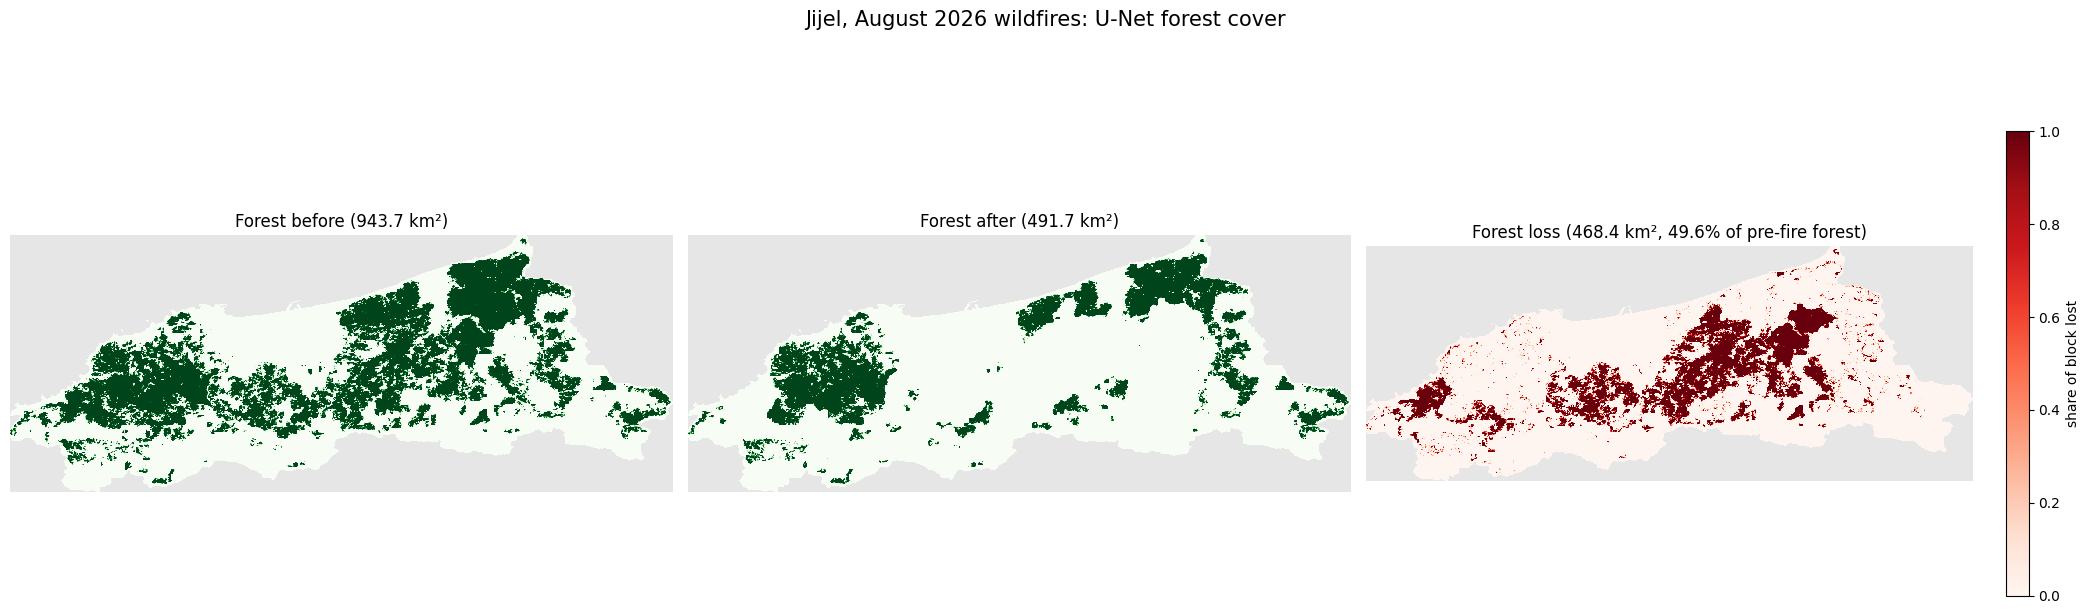

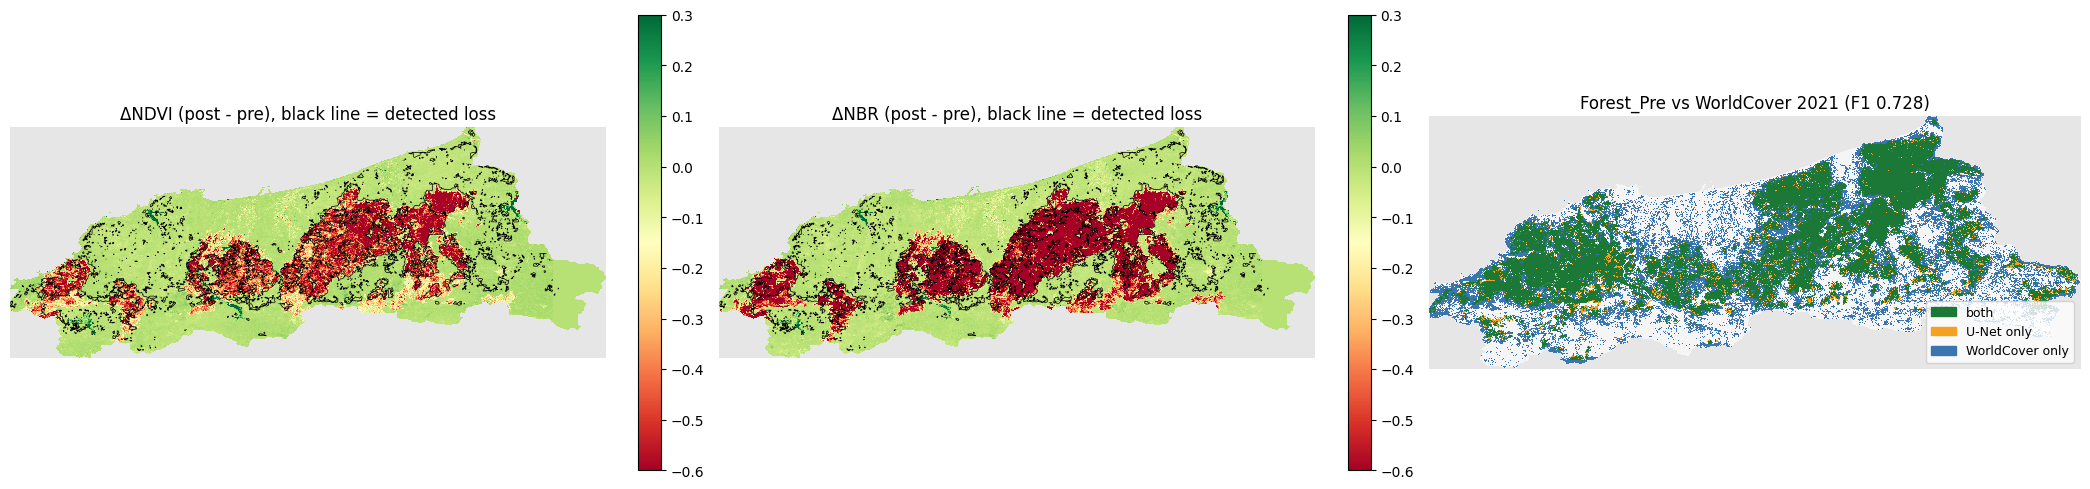

In [20]:
# %% 10. Maps
def block_reduce(arr, s, func=np.nanmean):
    h2, w2 = arr.shape[0] // s * s, arr.shape[1] // s * s
    blocks = arr[:h2, :w2].reshape(h2 // s, s, w2 // s, s)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        return func(blocks, axis=(1, 3))


def fraction(mask, s):
    """Share of the block covered by the mask (NaN outside the valid area)."""
    arr = np.where(valid, mask.astype(np.float32), np.float32(np.nan))
    return block_reduce(arr, s)


def cmap_with_bg(name):
    cm = plt.get_cmap(name).copy()
    cm.set_bad("#e6e6e6")
    return cm


s = CONFIG["DISPLAY_STEP"]
pre_c, post_c, loss_c = fraction(forest_pre, s), fraction(forest_post, s), fraction(loss, s)

fig, axes = plt.subplots(1, 3, figsize=(21, 7))
fig.suptitle("Jijel, August 2026 wildfires: U-Net forest cover", fontsize=15)
for ax, arr, title, cmap in (
        (axes[0], pre_c, f"Forest before ({A_pre:.1f} km²)", "Greens"),
        (axes[1], post_c, f"Forest after ({A_post:.1f} km²)", "Greens")):
    ax.imshow(arr, cmap=cmap_with_bg(cmap), vmin=0, vmax=1, interpolation="nearest")
    ax.set_title(title)
vmax = float(min(1.0, max(0.2, np.nanpercentile(loss_c, 99))))
im = axes[2].imshow(loss_c, cmap=cmap_with_bg("Reds"), vmin=0, vmax=vmax, interpolation="nearest")
axes[2].set_title(f"Forest loss ({A_loss:.1f} km², {pct_lost:.1f}% of pre-fire forest)")
fig.colorbar(im, ax=axes[2], fraction=0.035, label="share of block lost")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.savefig(OUT_DIR / "map_forest_loss.png", dpi=150, bbox_inches="tight")
plt.show()

# %% 11. Evidence maps and WorldCover agreement
dndvi_c, dnbr_c = block_reduce(d_ndvi, s), block_reduce(d_nbr, s)

agree = np.zeros((H, W), np.uint8)
agree[forest_pre & wc_forest] = 1        # both forest
agree[forest_pre & ~wc_forest] = 2       # U-Net only
agree[~forest_pre & wc_forest] = 3       # WorldCover only
agree = np.ma.masked_where(~wc_domain, agree)[::s, ::s]

fig, axes = plt.subplots(1, 3, figsize=(21, 7))
for ax, arr, title in ((axes[0], dndvi_c, "ΔNDVI (post - pre)"), (axes[1], dnbr_c, "ΔNBR (post - pre)")):
    im = ax.imshow(arr, cmap=cmap_with_bg("RdYlGn"), vmin=-0.6, vmax=0.3, interpolation="nearest")
    level = min(0.25, 0.5 * vmax)
    if np.nanmax(loss_c) > level:
        ax.contour(np.nan_to_num(loss_c, nan=0.0), levels=[level], colors="black", linewidths=0.5)
    ax.set_title(f"{title}, black line = detected loss")
    fig.colorbar(im, ax=ax, fraction=0.035)
agree_cmap = ListedColormap(["#f5f5f5", "#1b7837", "#f4a020", "#3b75af"])
agree_cmap.set_bad("#e6e6e6")
axes[2].imshow(agree, cmap=agree_cmap, vmin=0, vmax=3, interpolation="nearest")
axes[2].set_title(f"Forest_Pre vs WorldCover 2021 (F1 {wc_metrics['f1']:.3f})")
axes[2].legend(handles=[Patch(color="#1b7837", label="both"),
                        Patch(color="#f4a020", label="U-Net only"),
                        Patch(color="#3b75af", label="WorldCover only")],
               loc="lower right", fontsize=9)
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.savefig(OUT_DIR / "map_evidence_and_worldcover.png", dpi=150, bbox_inches="tight")
plt.show()